## Problem Statement

SafeDrive Insurance Ltd. has experienced an increase in insurance claim payouts and wants to better understand the factors associated with claim risk. Traditional underwriting methods rely heavily on manual assessment, which can lead to inconsistent risk evaluation.

The objective of this project is to analyse policyholder, vehicle, and safety-related information to identify patterns associated with insurance claims. The analysis will help determine which characteristics may be linked to a higher likelihood of a claim and provide useful insights for underwriting and risk management teams.

This notebook focuses on preparing and understanding the dataset through data cleaning, exploratory data analysis, and feature engineering. The analysis will examine the distribution of important variables, investigate their relationships with the claim outcome, identify potential data quality issues, and create meaningful features that may improve predictive modelling.

The findings from this stage will provide a reliable foundation for building and evaluating machine learning models in the subsequent stages of the project.

### Loading and understanding the dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [57]:
from pathlib import Path

filename = r"dataset.csv"

search_dirs = [
    Path.cwd(),
    Path.cwd() / "archive",
    Path("/mnt/user-data/uploads"),
    Path("/mnt/data"),
]

file_path = next(
    (folder / filename for folder in search_dirs
     if (folder / filename).is_file()),
    None
)

if file_path is None:
    raise FileNotFoundError(
        f"{filename} not found. Check the dataset filename and location."
    )

df = pd.read_csv(file_path)

print("Dataset loaded from:", file_path)


Dataset loaded from: c:\Users\kanwa\Downloads\capstone\dataset.csv


In [3]:
print("Dataset shape:", df.shape)


Dataset shape: (58592, 44)


In [4]:
display(df.head())

,policy_id,policy_tenure,age_of_car,age_of_policyholder,area_cluster,population_density,make,segment,model,fuel_type,...,is_brake_assist,is_power_door_locks,is_central_locking,is_power_steering,is_driver_seat_height_adjustable,is_day_night_rear_view_mirror,is_ecw,is_speed_alert,ncap_rating,is_claim
0,ID00001,0.515874,0.05,0.644231,C1,4990,1,A,M1,CNG,...,No,No,No,Yes,No,No,No,Yes,0,0
1,ID00002,0.672619,0.02,0.375000,C2,27003,1,A,M1,CNG,...,No,No,No,Yes,No,No,No,Yes,0,0
2,ID00003,0.841110,0.02,0.384615,C3,4076,1,A,M1,CNG,...,No,No,No,Yes,No,No,No,Yes,0,0
3,ID00004,0.900277,0.11,0.432692,C4,21622,1,C1,M2,Petrol,...,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,2,0
4,ID00005,0.596403,0.11,0.634615,C5,34738,2,A,M3,Petrol,...,No,Yes,Yes,Yes,No,Yes,Yes,Yes,2,0


In [5]:
df.info(verbose=True)

<class 'pandas.DataFrame'>
RangeIndex: 58592 entries, 0 to 58591
Data columns (total 44 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   policy_id                         58592 non-null  str    
 1   policy_tenure                     58592 non-null  float64
 2   age_of_car                        58592 non-null  float64
 3   age_of_policyholder               58592 non-null  float64
 4   area_cluster                      58592 non-null  str    
 5   population_density                58592 non-null  int64  
 6   make                              58592 non-null  int64  
 7   segment                           58592 non-null  str    
 8   model                             58592 non-null  str    
 9   fuel_type                         58592 non-null  str    
 10  max_torque                        58592 non-null  str    
 11  max_power                         58592 non-null  str    
 12  engine_type    

In [6]:
# Statistical summary
df.describe()

,policy_tenure,age_of_car,age_of_policyholder,population_density,make,airbags,displacement,cylinder,gear_box,turning_radius,length,width,height,gross_weight,ncap_rating,is_claim
count,58592.000000,58592.000000,58592.000000,58592.000000,58592.000000,58592.000000,58592.000000,58592.000000,58592.000000,58592.000000,58592.000000,58592.000000,58592.00000,58592.000000,58592.000000,58592.000000
mean,0.611246,0.069424,0.469420,18826.858667,1.763722,3.137066,1162.355851,3.626963,5.245443,4.852893,3850.476891,1672.233667,1553.33537,1385.276813,1.759950,0.063968
std,0.414156,0.056721,0.122886,17660.174792,1.136988,1.832641,266.304786,0.483616,0.430353,0.228061,311.457119,112.089135,79.62227,212.423085,1.389576,0.244698
min,0.002735,0.000000,0.288462,290.000000,1.000000,1.000000,796.000000,3.000000,5.000000,4.500000,3445.000000,1475.000000,1475.00000,1051.000000,0.000000,0.000000
25%,0.210250,0.020000,0.365385,6112.000000,1.000000,2.000000,796.000000,3.000000,5.000000,4.600000,3445.000000,1515.000000,1475.00000,1185.000000,0.000000,0.000000
50%,0.573792,0.060000,0.451923,8794.000000,1.000000,2.000000,1197.000000,4.000000,5.000000,4.800000,3845.000000,1735.000000,1530.00000,1335.000000,2.000000,0.000000
75%,1.039104,0.110000,0.548077,27003.000000,3.000000,6.000000,1493.000000,4.000000,5.000000,5.000000,3995.000000,1755.000000,1635.00000,1510.000000,3.000000,0.000000
max,1.396641,1.000000,1.000000,73430.000000,5.000000,6.000000,1498.000000,4.000000,6.000000,5.200000,4300.000000,1811.000000,1825.00000,1720.000000,5.000000,1.000000


In [7]:
# Data type counts
print("Data type counts:")
print(df.dtypes.value_counts())

Data type counts:
str        28
int64      12
float64     4
Name: count, dtype: int64


In [8]:
# Data type of each column
display(df.dtypes.rename("dtype").to_frame())

,dtype
policy_id,str
policy_tenure,float64
age_of_car,float64
age_of_policyholder,float64
area_cluster,str
population_density,int64
make,int64
segment,str
model,str
fuel_type,str


In [9]:
df.columns

Index(['policy_id', 'policy_tenure', 'age_of_car', 'age_of_policyholder',
       'area_cluster', 'population_density', 'make', 'segment', 'model',
       'fuel_type', 'max_torque', 'max_power', 'engine_type', 'airbags',
       'is_esc', 'is_adjustable_steering', 'is_tpms', 'is_parking_sensors',
       'is_parking_camera', 'rear_brakes_type', 'displacement', 'cylinder',
       'transmission_type', 'gear_box', 'steering_type', 'turning_radius',
       'length', 'width', 'height', 'gross_weight', 'is_front_fog_lights',
       'is_rear_window_wiper', 'is_rear_window_washer',
       'is_rear_window_defogger', 'is_brake_assist', 'is_power_door_locks',
       'is_central_locking', 'is_power_steering',
       'is_driver_seat_height_adjustable', 'is_day_night_rear_view_mirror',
       'is_ecw', 'is_speed_alert', 'ncap_rating', 'is_claim'],
      dtype='str')

* The columns make, airbags, cylinder, and gear_box will be converted to categorical data types because they represent distinct categories rather than continuous numerical values. We will apply One-Hot Encoding to these columns before model training. The target column is_claim is also categorical, but we will keep it unchanged for now for numerical analysis.


In [10]:
cols_to_convert = ['make', 'airbags','cylinder', 'gear_box'] # coverting these columns to category type
for col in cols_to_convert:
    df[col] = df[col].astype('category')  

##### Checking Missing Values

In [11]:
# Missing values per column
print("Missing values:")
display(df.isnull().sum().to_frame("missing_count"))

Missing values:


,missing_count
policy_id,0
policy_tenure,0
age_of_car,0
age_of_policyholder,0
area_cluster,0
population_density,0
make,0
segment,0
model,0
fuel_type,0


In [12]:
df.isnull().sum().sum()

np.int64(0)

##### Checking duplicate values

In [13]:
# Exact duplicate rows
print("Duplicate row count:", df.duplicated().sum())

Duplicate row count: 0


In [14]:
# Duplicate policy IDs
print(
    "Duplicate policy_id count:",
    df["policy_id"].duplicated().sum()
)

Duplicate policy_id count: 0


##### Checking Target Distribution

In [15]:
# Target distribution
counts = df["is_claim"].value_counts().sort_index()
print("Claim counts:")
print(counts)

Claim counts:
is_claim
0    54844
1     3748
Name: count, dtype: int64


In [16]:
print("\nClaim percentages:")
print((df["is_claim"].value_counts(normalize=True) * 100).sort_index())


Claim percentages:
is_claim
0    93.603222
1     6.396778
Name: proportion, dtype: float64


- The target column is_claim is imbalanced, with significantly more non-claim cases than claim cases. Therefore, we will focus on precision, recall, and F1-score rather than relying on accuracy alone to evaluate model performance.

In [17]:
# Majority class / minority class
imbalance_ratio = counts.max() / counts.min()
print("\nClass imbalance ratio:", round(imbalance_ratio, 2))


Class imbalance ratio: 14.63


##### Extracting `max_power_bhp` and `max_torque_nm`

- Extracted the leading numeric values from `max_power` and `max_torque` into new numeric columns, `max_power_bhp` and `max_torque_nm`.
- Converted the extracted values to numeric data types for further analysis and modelling.

In [18]:
import re

def extract_leading_number(value):
    if pd.isna(value):
        return np.nan

    match = re.match(
        r"^\s*([-+]?(?:\d+(?:\.\d*)?|\.\d+))",
        str(value)
    )

    return float(match.group(1)) if match else np.nan


df["max_power_bhp"] = (
    df["max_power"].apply(extract_leading_number)
)

df["max_torque_nm"] = (
    df["max_torque"].apply(extract_leading_number)
)

display(
    df[
        ["max_power", "max_power_bhp",
         "max_torque", "max_torque_nm"]
    ].head(10)
)

,max_power,max_power_bhp,max_torque,max_torque_nm
0,40.36bhp@6000rpm,40.36,60Nm@3500rpm,60.0
1,40.36bhp@6000rpm,40.36,60Nm@3500rpm,60.0
2,40.36bhp@6000rpm,40.36,60Nm@3500rpm,60.0
3,88.50bhp@6000rpm,88.50,113Nm@4400rpm,113.0
4,67.06bhp@5500rpm,67.06,91Nm@4250rpm,91.0
5,113.45bhp@4000rpm,113.45,250Nm@2750rpm,250.0
6,88.77bhp@4000rpm,88.77,200Nm@3000rpm,200.0
7,88.50bhp@6000rpm,88.50,113Nm@4400rpm,113.0
8,113.45bhp@4000rpm,113.45,250Nm@2750rpm,250.0
9,88.50bhp@6000rpm,88.50,113Nm@4400rpm,113.0


### **EDA**

##### Univariate Analysis

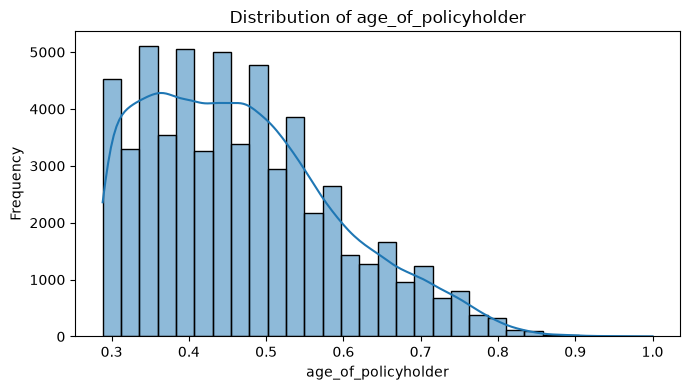

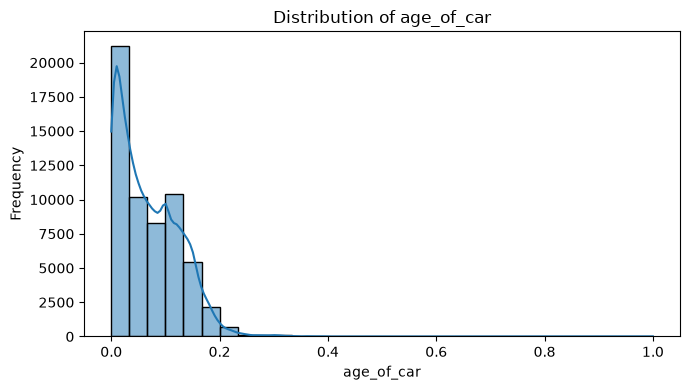

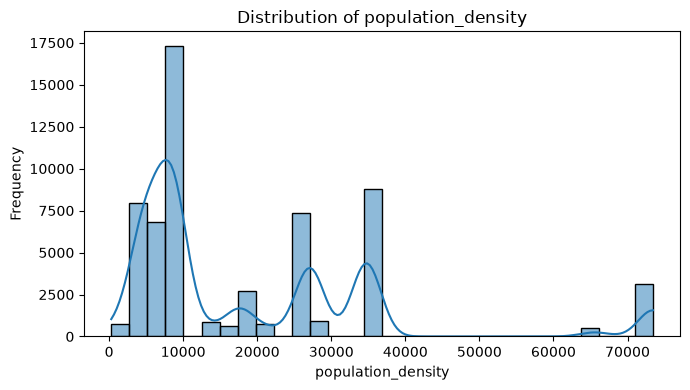

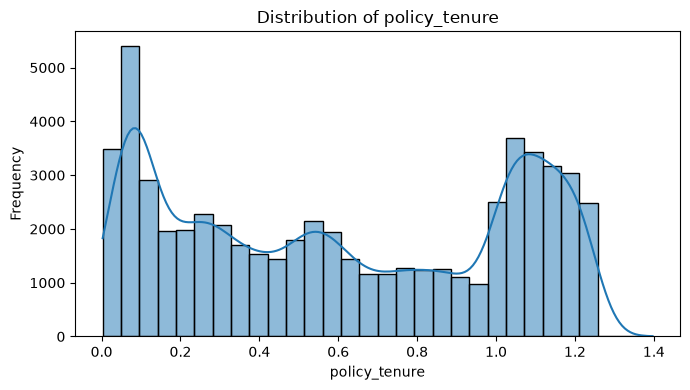

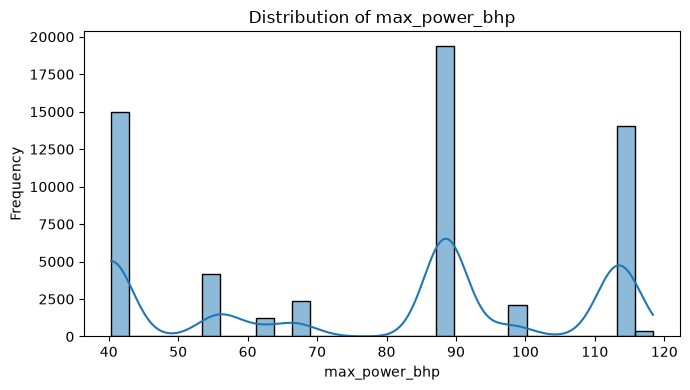

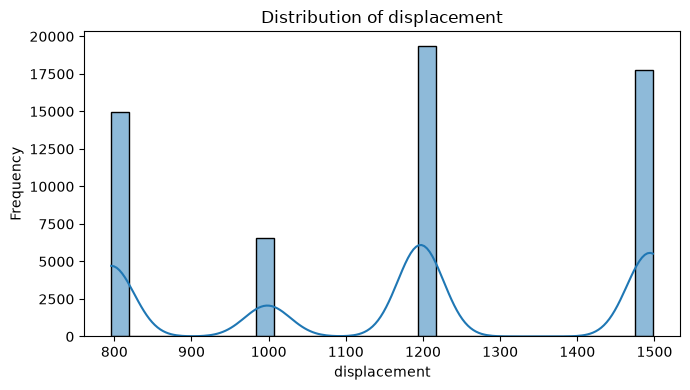

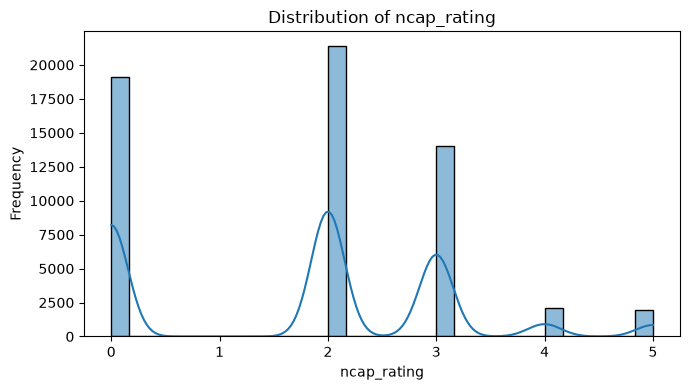

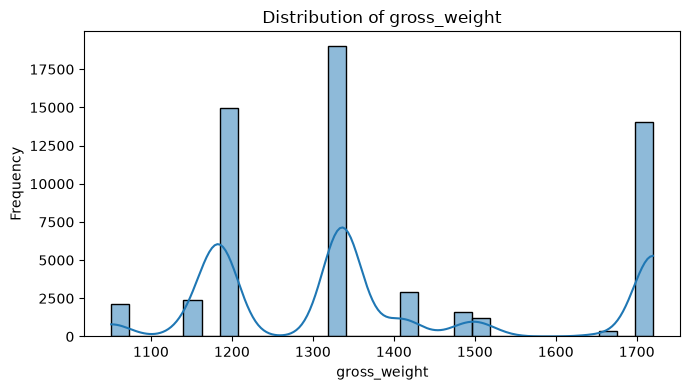

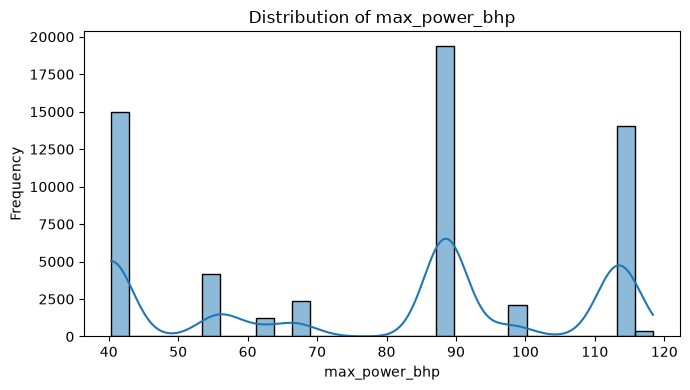

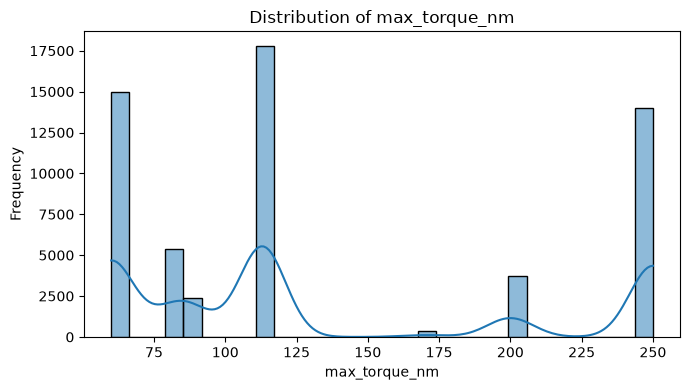

In [19]:
numeric_plot_cols = [
    "age_of_policyholder",
    "age_of_car",
    "population_density",
    "policy_tenure",
    "max_power_bhp",
    "displacement",
    "ncap_rating",
    "gross_weight",
    "max_power_bhp",
    "max_torque_nm"
]

numeric_plot_cols = [
    col for col in numeric_plot_cols
    if col in df.columns
]

for col in numeric_plot_cols:
    values = pd.to_numeric(df[col], errors="coerce").dropna()

    plt.figure(figsize=(7, 4))
    sns.histplot(values, kde=True, bins=30)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

- `age_of_car` and `age_of_policyholder` show right-skewed distributions, with most observations concentrated at lower values and a tail extending towards higher values.
- The other numerical features show multimodal distributions, indicating multiple peaks that may reflect different groups or patterns in the data.

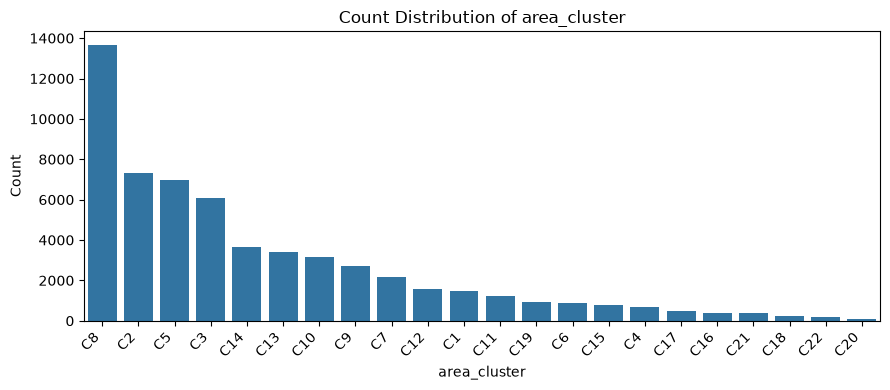

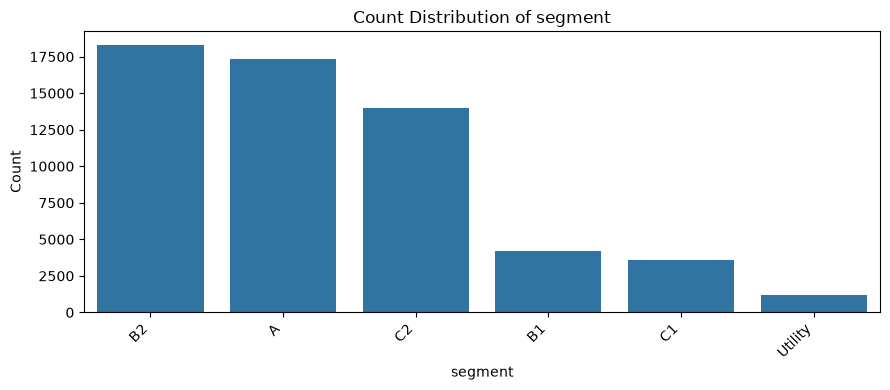

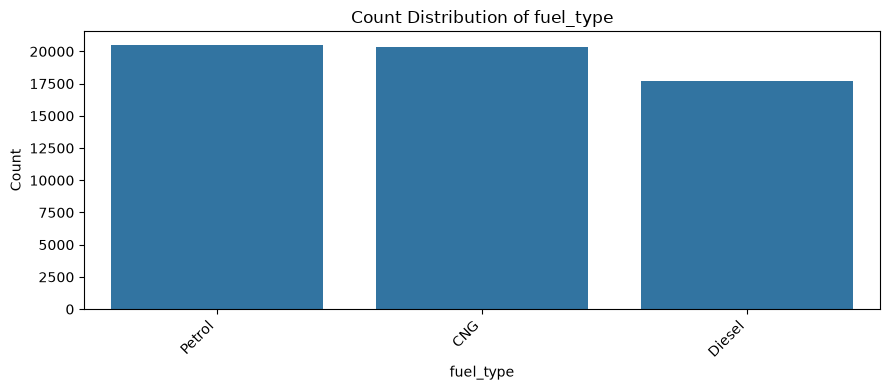

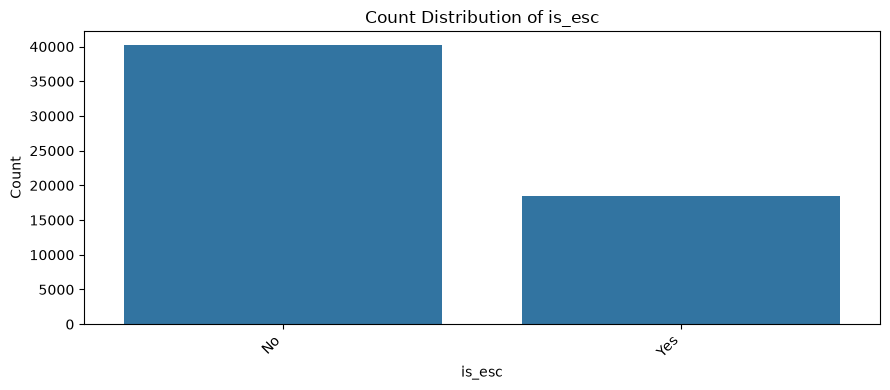

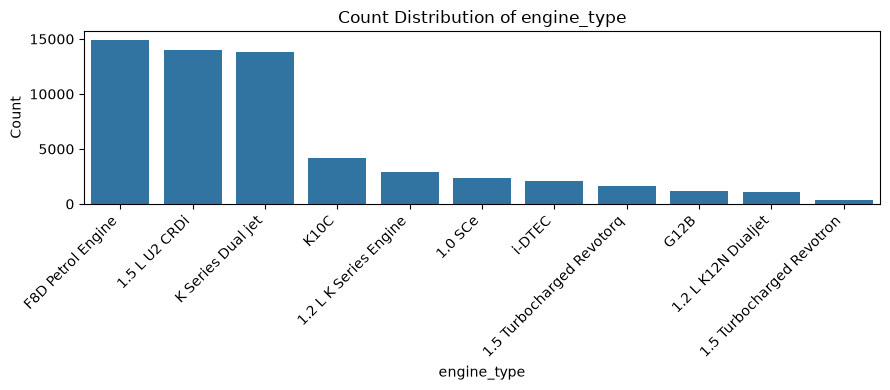

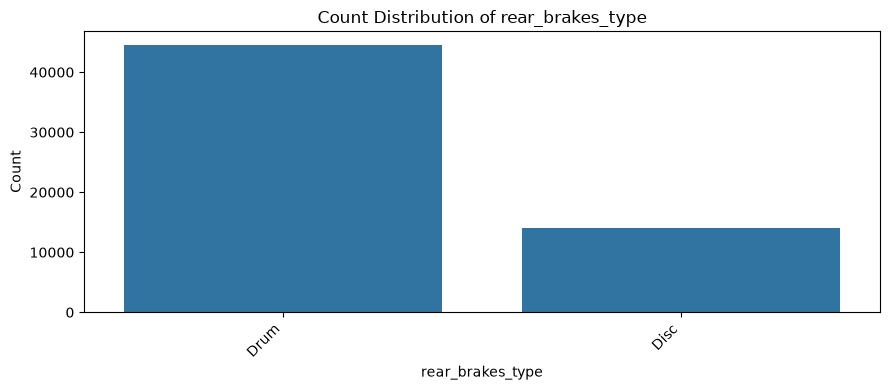

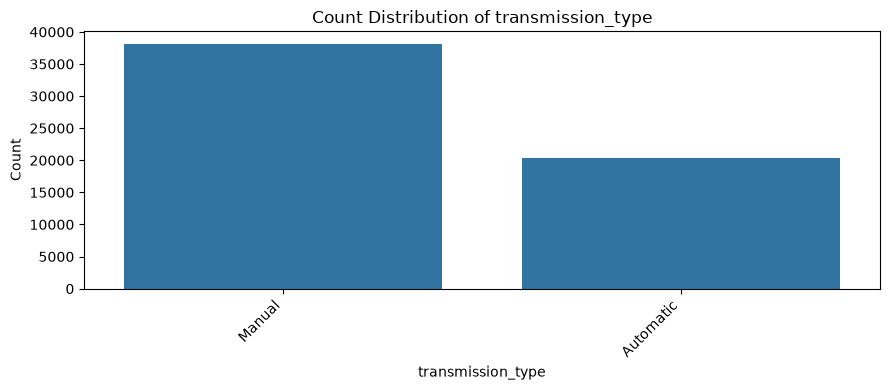

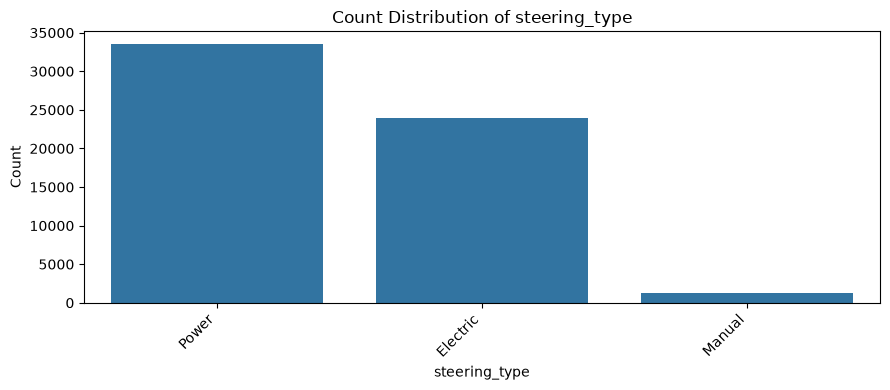

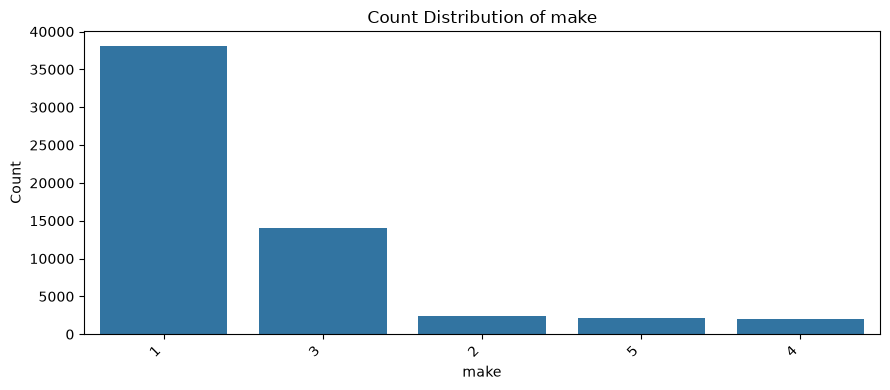

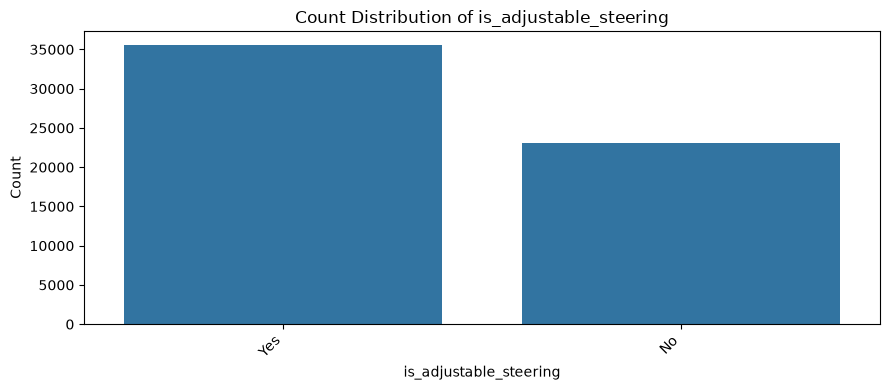

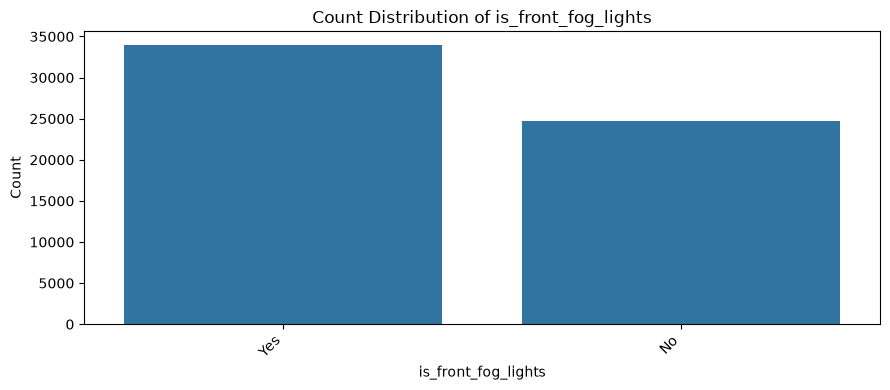

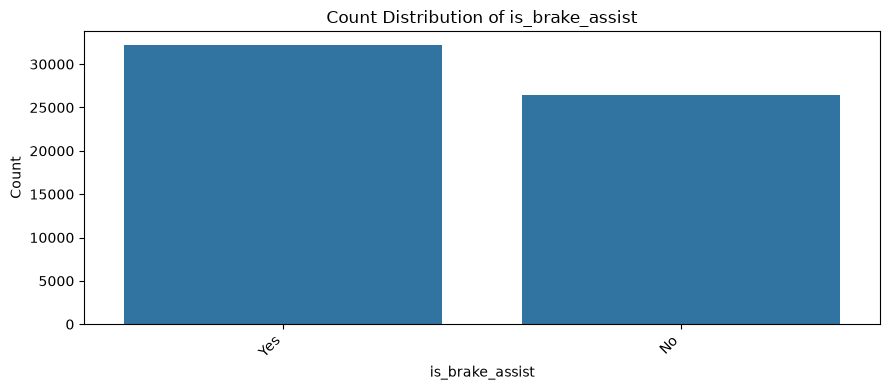

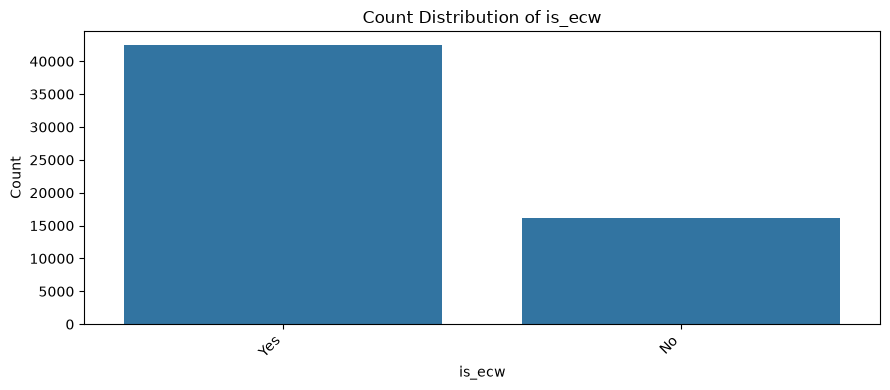

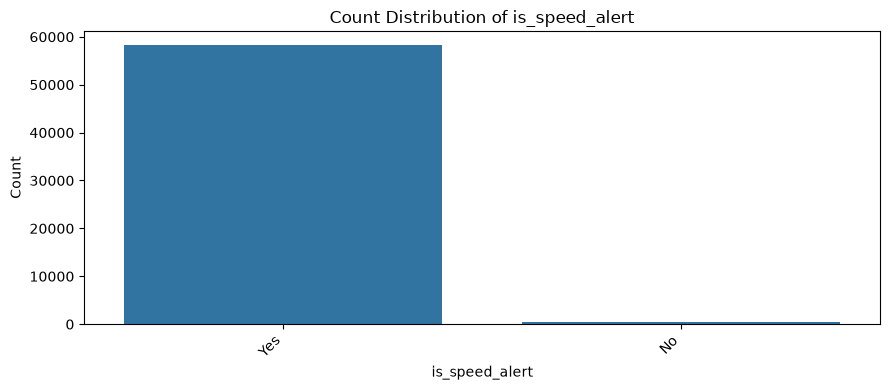

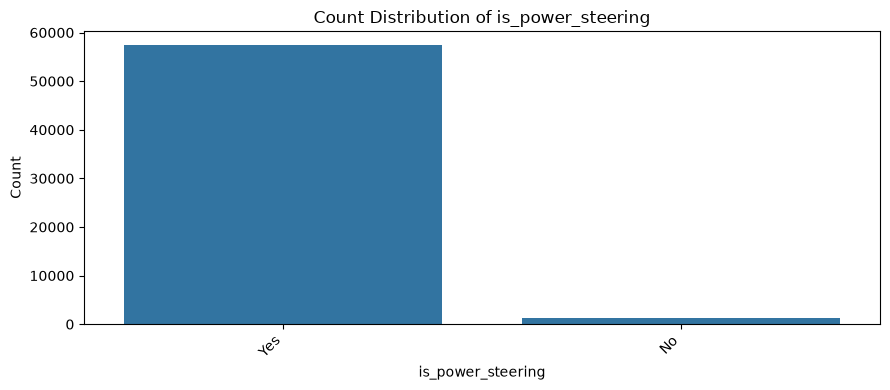

In [20]:
categorical_plot_cols = [
    "area_cluster",
    "segment",
    "fuel_type",
    'is_esc',
    "engine_type",
    "rear_brakes_type",
    "transmission_type",
    "steering_type",
    "make",
    'is_adjustable_steering',
    'is_front_fog_lights',
    'is_brake_assist',
    'is_ecw',
    'is_speed_alert',
    'is_power_steering'
]

categorical_plot_cols = [
    col for col in categorical_plot_cols if col in df.columns
]

for col in categorical_plot_cols:
    plt.figure(figsize=(9, 4))

    order = df[col].value_counts().index

    sns.countplot(data=df, x=col, order=order)

    plt.title(f"Count Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

- Features such as `is_speed_alert` and `is_power_steering` are almost entirely "Yes" and carry little information.

In [21]:
print(pd.crosstab(df['steering_type'], df['is_power_steering']))

is_power_steering    No    Yes
steering_type                 
Electric              0  23881
Manual             1209      0
Power                 0  33502


In [22]:
df = df.drop(columns=['is_power_steering'])

The columns `steering_type` and `is_power_steering` contain redundant information, so one of them was dropped to avoid duplication.

In [23]:
# does each model map to exactly one make and one segment?
print(df.groupby('model')[['make','segment']].nunique().max())

# does each make map to one segment, or one model?
print(df.groupby('make')[['model','segment']].nunique())
print(df.groupby('segment')[['model','make']].nunique())

make       1
segment    1
dtype: int64
      model  segment
make                
1         6        5
2         1        1
3         1        1
4         2        2
5         1        1
         model  make
segment             
A            2     2
B1           1     1
B2           3     2
C1           3     3
C2           1     1
Utility      1     1


In [24]:
df = df.drop(columns=['make', 'model'])

- `make` and `model` were dropped because `model` fully determines `make`, `segment` and the vehicle-spec columns, so they add only redundant information.

- Correlation Analysis

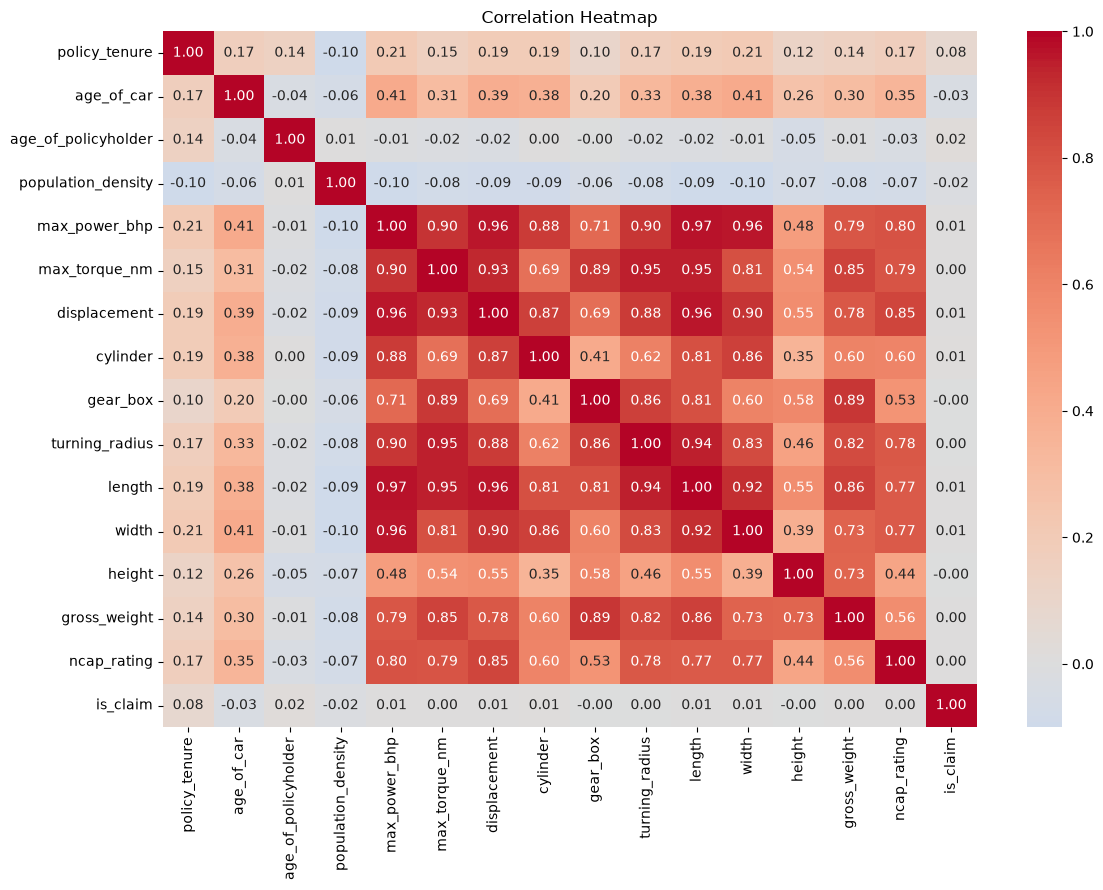

In [25]:
#Correlation heatmap
corr_cols = [
    "policy_tenure",
    "age_of_car",
    "age_of_policyholder",
    "population_density",
    "max_power_bhp",
    "max_torque_nm",
    "displacement",
    "cylinder",
    "gear_box",
    "turning_radius",
    "length",
    "width",
    "height",
    "gross_weight",
    "ncap_rating",
    "is_claim",
]

corr_cols = [
    col for col in corr_cols if col in df.columns
]

corr_data = df[corr_cols].apply(
    pd.to_numeric, errors="coerce"
)

corr_matrix = corr_data.corr()

plt.figure(figsize=(12, 9))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

- The numerical features show relatively weak linear correlations with `is_claim`, suggesting limited individual linear relationships with claim status. However, these features may still contribute to predictive performance through nonlinear patterns or interactions. Further feature engineering and model-based feature selection can help identify useful predictors.

In [26]:
#Rank predictors by absolute correlation with is_claim
target_corr = (
    corr_matrix["is_claim"]
    .drop("is_claim")
    .dropna()
    .to_frame("correlation_with_is_claim")
)

target_corr["absolute_correlation"] = (
    target_corr["correlation_with_is_claim"].abs()
)

target_corr = target_corr.sort_values(
    "absolute_correlation",
    ascending=False
)

display(target_corr)

,correlation_with_is_claim,absolute_correlation
policy_tenure,0.078747,0.078747
age_of_car,-0.028172,0.028172
age_of_policyholder,0.022435,0.022435
population_density,-0.017808,0.017808
cylinder,0.013434,0.013434
width,0.009947,0.009947
max_power_bhp,0.007698,0.007698
displacement,0.007678,0.007678
length,0.006495,0.006495
max_torque_nm,0.004294,0.004294


#### claim rate vs. key predictors

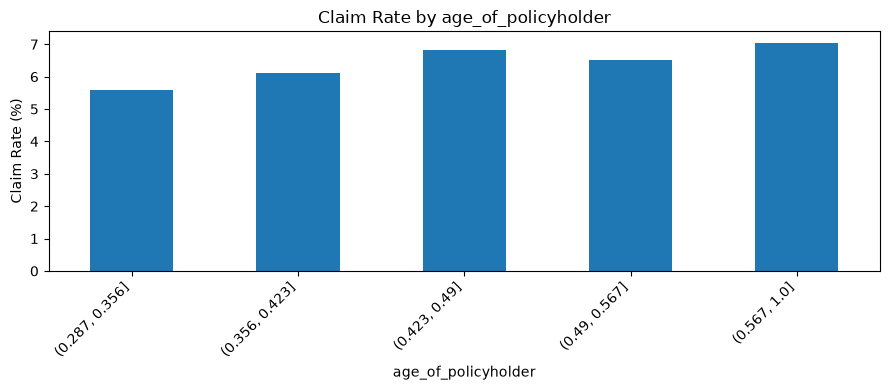

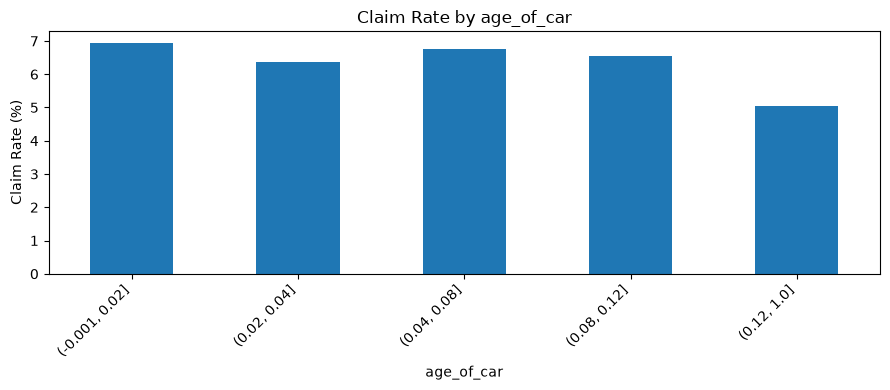

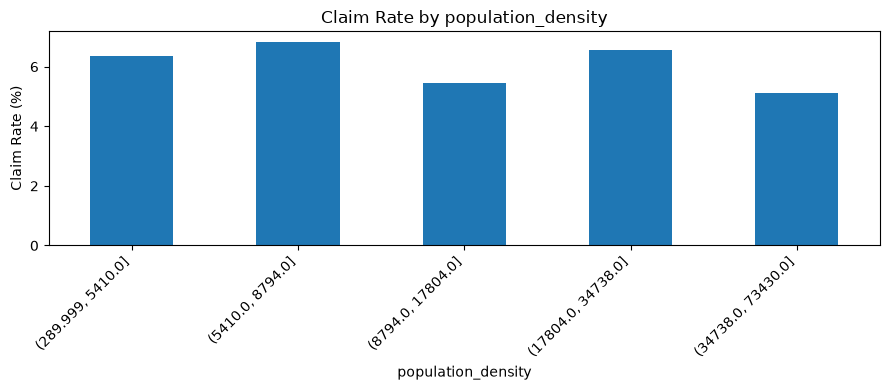

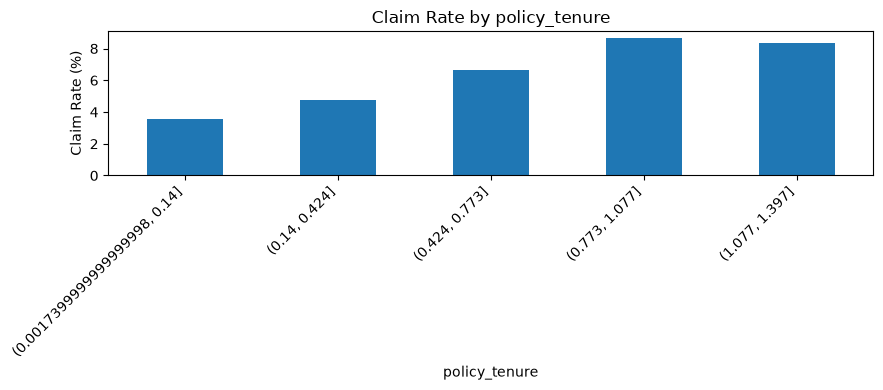

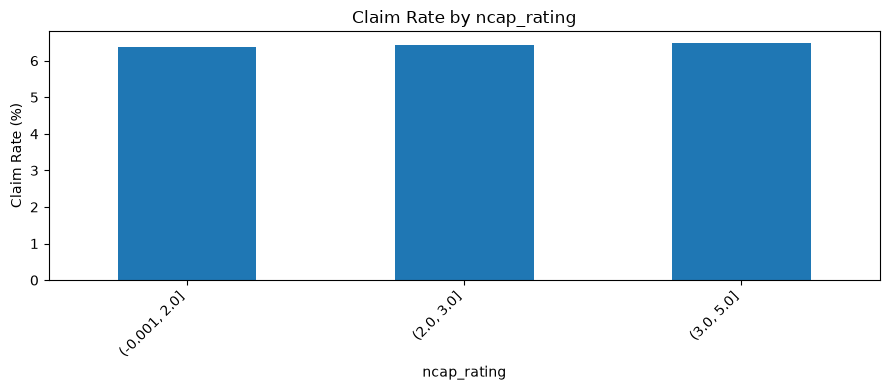

In [27]:
continuous_cols = [
    'age_of_policyholder',
    'age_of_car',
    'population_density',
    'policy_tenure',
    'ncap_rating'

]

for col in continuous_cols:
    temp = df[[col, 'is_claim']].dropna().copy()

    temp['bin'] = pd.qcut(
        temp[col],
        q=5,
        duplicates='drop'
    )

    claim_rate = (
        temp.groupby('bin', observed=False)['is_claim']
        .mean()
        .mul(100)
        .round(3)
    )


    plt.figure(figsize=(9, 4))
    claim_rate.plot(kind='bar')

    plt.title(f'Claim Rate by {col}')
    plt.xlabel(col)
    plt.ylabel('Claim Rate (%)')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()


- **Claim rate by age_of_policyholder, age_of_car and population_density:** Claim rates stay in a narrow band of roughly 5-7% across all bins of these three features, with no strong or consistent trend. Claim rate rises slightly with policyholder age (about 5.6% to 7%), drops for the oldest cars (about 5%), and varies unevenly across population density bins (about 5.1% to 6.8%). None of these features is a strong standalone predictor, though they may still help through interactions with other variables.
- **Policy tenure** is the strongest claim driver: the claim rate rises from about 3.5% in the shortest-tenure quintile to about 8.7% in the second-longest (about 2.5×), and it has the highest correlation with `is_claim` (r = 0.079), reflecting longer exposure to risk.

##### Claim rate by categorical predictors

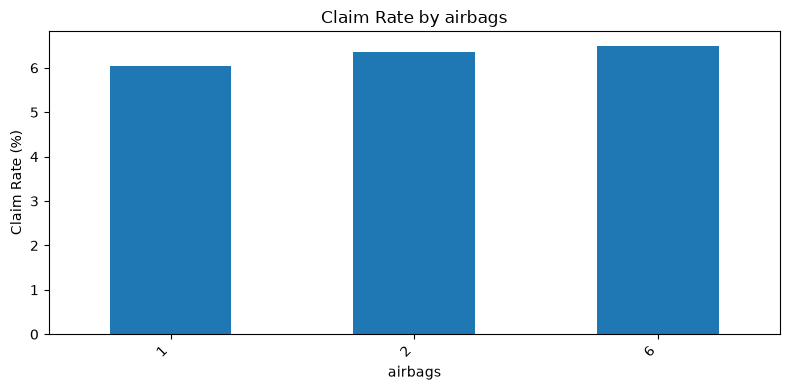

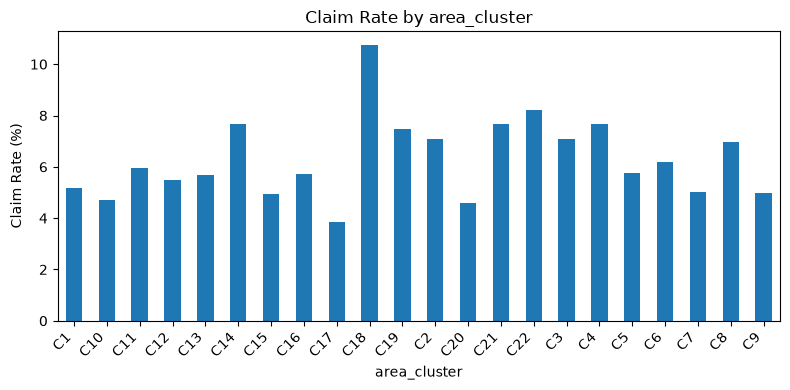

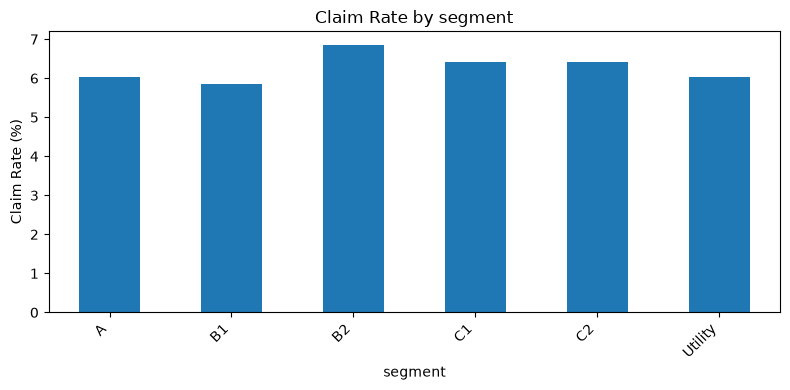

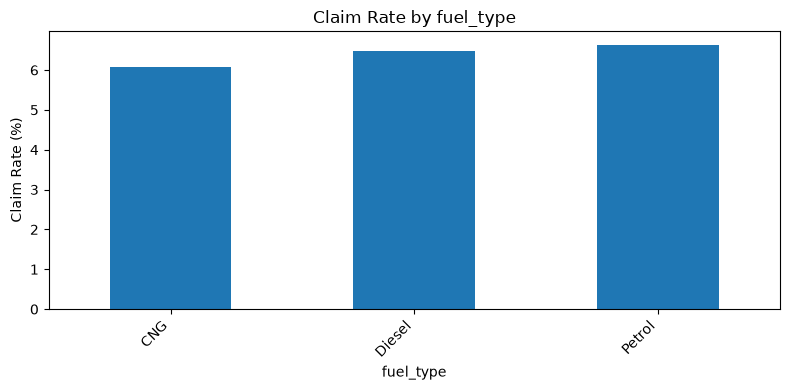

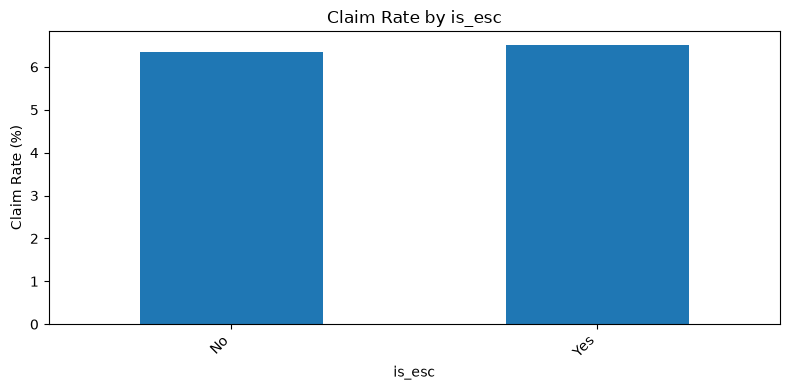

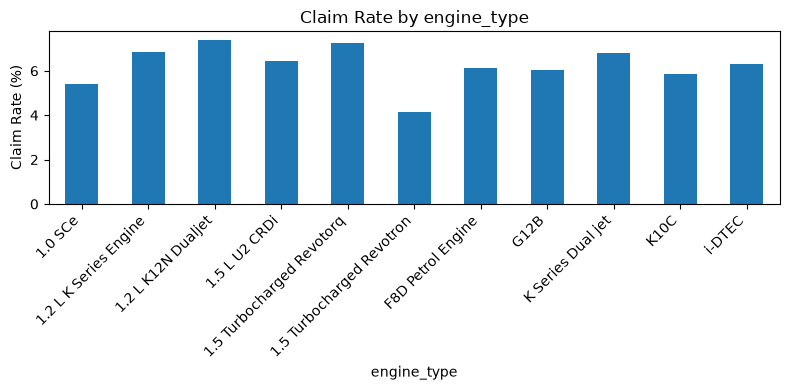

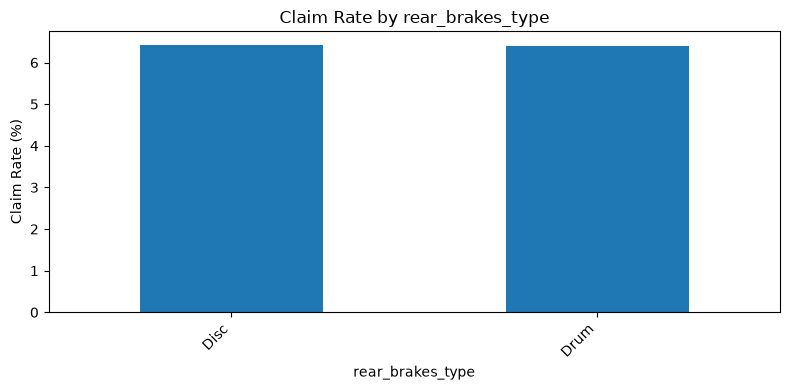

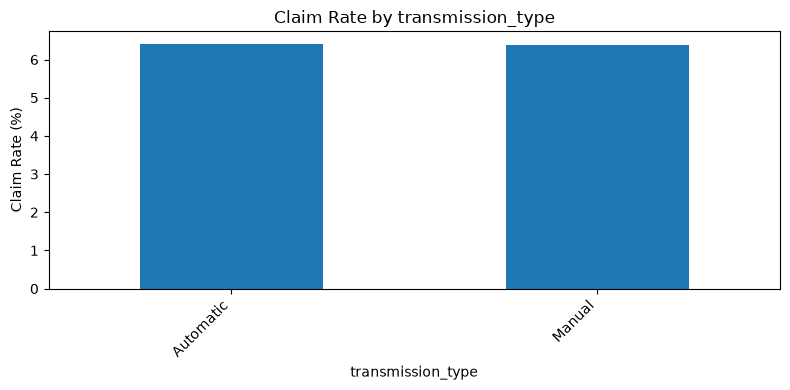

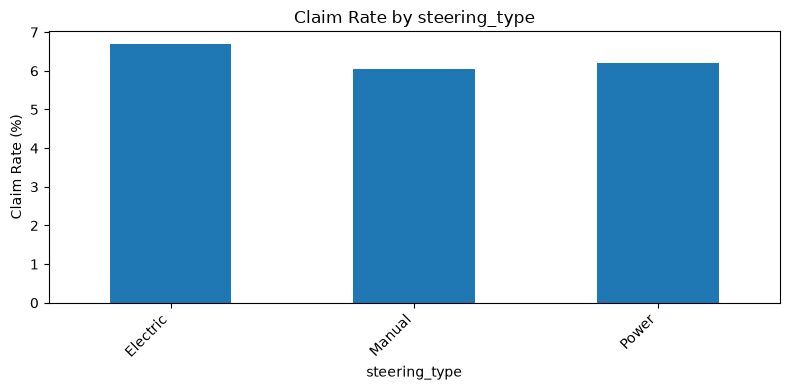

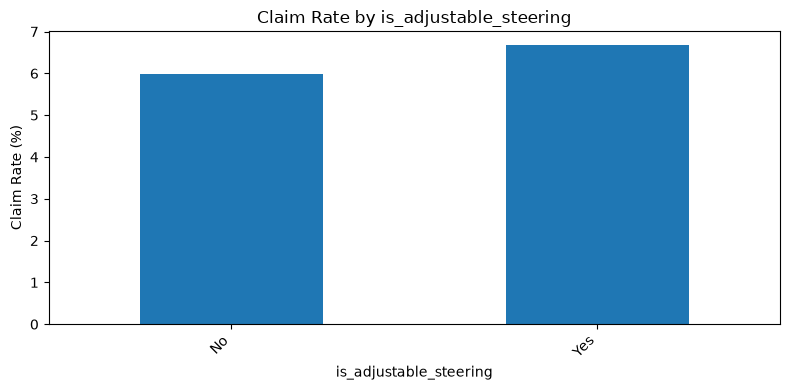

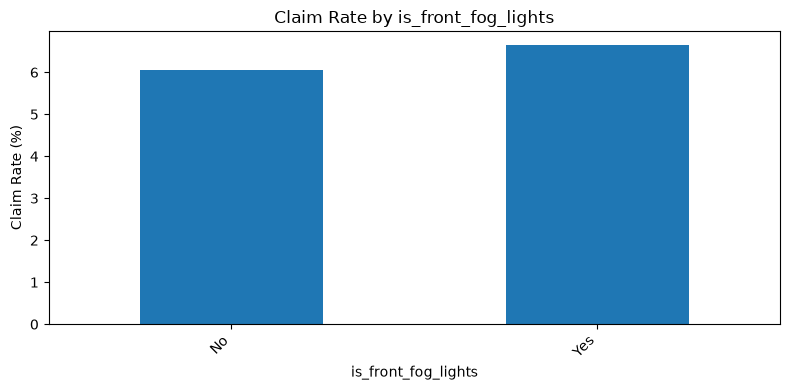

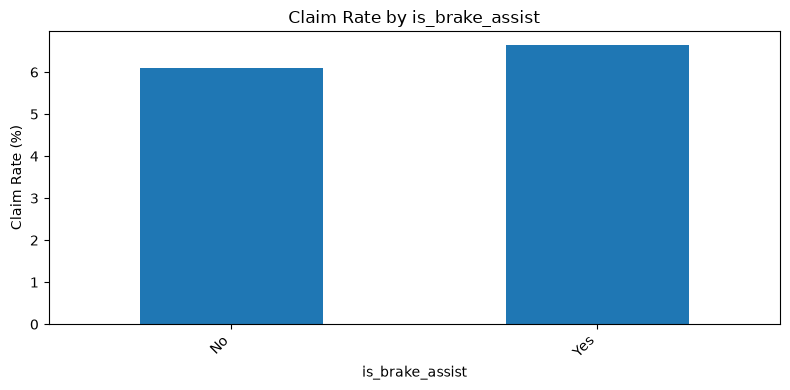

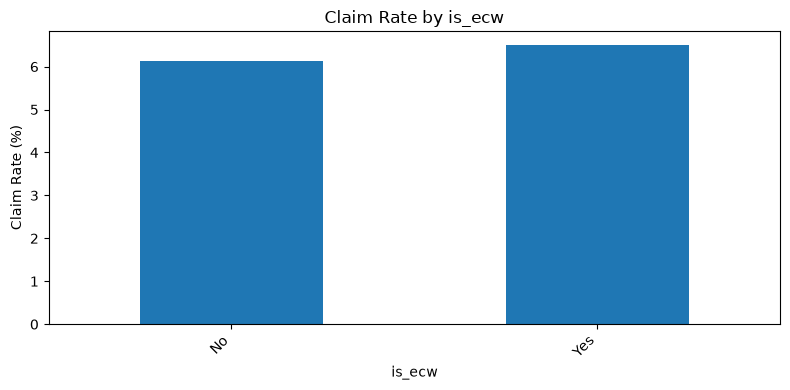

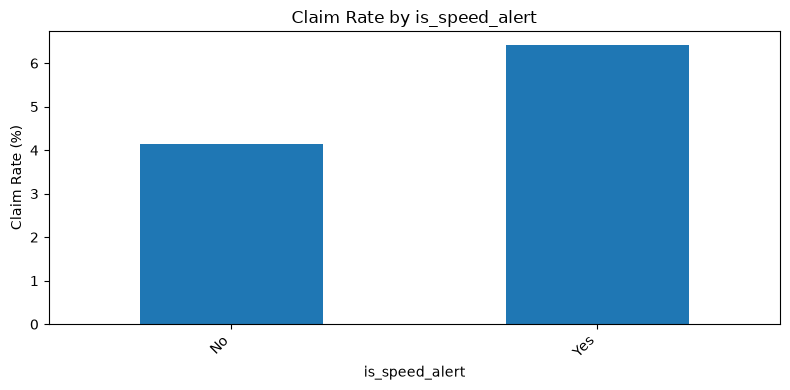

In [28]:
# Claim rate by is_speed_alert, segment, fuel_type, transmission_type
categorical_cols = [
    'airbags',
    "area_cluster",
        "segment",
        "fuel_type",
        'is_esc',
        "engine_type",
        "rear_brakes_type",
        "transmission_type",
        "steering_type",
        'is_adjustable_steering',
        'is_front_fog_lights',
        'is_brake_assist',
        'is_ecw',
        'is_speed_alert',
]

for col in categorical_cols:
    claim_rate = (
        df.groupby(col, observed=False)['is_claim']
        .mean()
        .mul(100)
    )

    plt.figure(figsize=(8, 4))
    claim_rate.plot(kind='bar')

    plt.title(f'Claim Rate by {col}')
    plt.xlabel(col)
    plt.ylabel('Claim Rate (%)')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

- **Speed alert:** Claim rates are approximately 6.4% with speed alert versus 4.1% without, a relative increase of around 55%, suggesting useful predictive potential.
- **Segment and fuel type:** Claim rates vary only slightly across categories, indicating limited standalone influence.
- **Transmission type:** Claim rates are nearly identical across categories, though these features may still contribute through interactions with other variables.

In [29]:
for col in ["area_cluster", "segment"]:
    g = df.groupby(col)["is_claim"].agg(policies="count", claims="sum", rate="mean")
    g["rate_%"] = (g["rate"] * 100).round(2)
    g["lift_vs_avg"] = (g["rate"] / df["is_claim"].mean()).round(2)
    g["ci95_±pp"] = (196 * (g["rate"] * (1 - g["rate"]) / g["policies"]) ** 0.5).round(2)
    print(g.sort_values("rate", ascending=False).drop(columns="rate"), "\n")

              policies  claims  rate_%  lift_vs_avg  ci95_±pp
area_cluster                                                 
C18                242      26   10.74         1.68      3.90
C22                207      17    8.21         1.28      3.74
C14               3660     281    7.68         1.20      0.86
C4                 665      51    7.67         1.20      2.02
C21                379      29    7.65         1.20      2.68
C19                952      71    7.46         1.17      1.67
C3                6101     433    7.10         1.11      0.64
C2                7342     520    7.08         1.11      0.59
C8               13654     954    6.99         1.09      0.43
C6                 890      55    6.18         0.97      1.58
C11               1212      72    5.94         0.93      1.33
C5                6979     403    5.77         0.90      0.55
C16                401      23    5.74         0.90      2.28
C13               3423     195    5.70         0.89      0.78
C12     

- **Area cluster** shows a wide spread around the 6.4% average, from 3.86% (C17) to 10.74% (C18), a gap of about 2.8×.
- **Reliably higher-risk clusters** are C14 (7.68%, 3,660 policies), C8 (6.99%, 13,654), C3 (7.10%) and C2 (7.08%), whose 95% intervals sit above average; C18 (242 policies, ±3.9 pp) and C22 (207 policies, ±3.7 pp) have the highest rates but too little data to be firm, so treat them as a watch-list.
- **Reliably lower-risk clusters** are C10 (4.69%), C9 (4.97%), C7 (5.03%) and C5 (5.77%), with intervals below average, while C17 (3.86%) and C20 (4.59%) look low but are based on small groups.
- **NCAP rating** shows no effect, with claim rates flat at about 6.4–6.5% across bins (r = 0.004), and vehicle segment adds little (5.85% for B1 to 6.86% for B2, about 0.9–1.1× average).

#### Preprocessing

In [30]:
df_clean = df.copy()

before = len(df_clean)
df_clean = df_clean.drop_duplicates().copy()
after = len(df_clean)

print("Rows before:", before)
print("Rows after:", after)
print("Rows removed:", before - after)

Rows before: 58592
Rows after: 58592
Rows removed: 0


In [31]:
# Check current data types
print(df_clean.dtypes)

# Identify object columns
object_cols = df_clean.select_dtypes(include=["object","category"]).columns
print("Object columns:", list(object_cols))

policy_id                                str
policy_tenure                        float64
age_of_car                           float64
age_of_policyholder                  float64
area_cluster                             str
population_density                     int64
segment                                  str
fuel_type                                str
max_torque                               str
max_power                                str
engine_type                              str
airbags                             category
is_esc                                   str
is_adjustable_steering                   str
is_tpms                                  str
is_parking_sensors                       str
is_parking_camera                        str
rear_brakes_type                         str
displacement                           int64
cylinder                            category
transmission_type                        str
gear_box                            category
steering_t

##### Standardize binary Yes/No columns

In [32]:
yes_no_columns = []

for col in df_clean.select_dtypes(include=["object", "category","string"]).columns:
    values = set(
        df_clean[col].astype(str).str.strip().str.lower()
    )

    if values and values.issubset({"yes", "no"}):
        yes_no_columns.append(col)

print("Detected Yes/No columns:", yes_no_columns)

for col in yes_no_columns:
    df_clean[col] = (
        df_clean[col].astype("string").str.strip().str.title()
    )

# Verify
for col in yes_no_columns:
    print(f"\n{col}:")
    print(df_clean[col].value_counts(dropna=False))

Detected Yes/No columns: ['is_esc', 'is_adjustable_steering', 'is_tpms', 'is_parking_sensors', 'is_parking_camera', 'is_front_fog_lights', 'is_rear_window_wiper', 'is_rear_window_washer', 'is_rear_window_defogger', 'is_brake_assist', 'is_power_door_locks', 'is_central_locking', 'is_driver_seat_height_adjustable', 'is_day_night_rear_view_mirror', 'is_ecw', 'is_speed_alert']

is_esc:
is_esc
No     40191
Yes    18401
Name: count, dtype: Int64

is_adjustable_steering:
is_adjustable_steering
Yes    35526
No     23066
Name: count, dtype: Int64

is_tpms:
is_tpms
No     44574
Yes    14018
Name: count, dtype: Int64

is_parking_sensors:
is_parking_sensors
Yes    56219
No      2373
Name: count, dtype: Int64

is_parking_camera:
is_parking_camera
No     35704
Yes    22888
Name: count, dtype: Int64

is_front_fog_lights:
is_front_fog_lights
Yes    33928
No     24664
Name: count, dtype: Int64

is_rear_window_wiper:
is_rear_window_wiper
No     41634
Yes    16958
Name: count, dtype: Int64

is_rear_windo

- The columns `is_rear_window_wiper` and `is_rear_window_washer`, as well as `is_power_door_locks` and `is_central_locking`, have identical value distributions. We will check whether these columns contain identical values row-wise to identify redundant features and avoid unnecessary duplication during model training.

In [33]:
df_clean.columns

Index(['policy_id', 'policy_tenure', 'age_of_car', 'age_of_policyholder',
       'area_cluster', 'population_density', 'segment', 'fuel_type',
       'max_torque', 'max_power', 'engine_type', 'airbags', 'is_esc',
       'is_adjustable_steering', 'is_tpms', 'is_parking_sensors',
       'is_parking_camera', 'rear_brakes_type', 'displacement', 'cylinder',
       'transmission_type', 'gear_box', 'steering_type', 'turning_radius',
       'length', 'width', 'height', 'gross_weight', 'is_front_fog_lights',
       'is_rear_window_wiper', 'is_rear_window_washer',
       'is_rear_window_defogger', 'is_brake_assist', 'is_power_door_locks',
       'is_central_locking', 'is_driver_seat_height_adjustable',
       'is_day_night_rear_view_mirror', 'is_ecw', 'is_speed_alert',
       'ncap_rating', 'is_claim', 'max_power_bhp', 'max_torque_nm'],
      dtype='str')

In [34]:
num_cols = df_clean.select_dtypes(include=['number']).columns.tolist()
num_cols.remove('is_claim')

print(num_cols)

['policy_tenure', 'age_of_car', 'age_of_policyholder', 'population_density', 'displacement', 'turning_radius', 'length', 'width', 'height', 'gross_weight', 'ncap_rating', 'max_power_bhp', 'max_torque_nm']


In [35]:
# Convert numeric-looking columns where appropriate
for col in num_cols:
    if col in df_clean.columns:
        df_clean[col] = pd.to_numeric(
            df_clean[col], errors="coerce"
        )

print(df_clean.dtypes)

policy_id                                str
policy_tenure                        float64
age_of_car                           float64
age_of_policyholder                  float64
area_cluster                             str
population_density                     int64
segment                                  str
fuel_type                                str
max_torque                               str
max_power                                str
engine_type                              str
airbags                             category
is_esc                                string
is_adjustable_steering                string
is_tpms                               string
is_parking_sensors                    string
is_parking_camera                     string
rear_brakes_type                         str
displacement                           int64
cylinder                            category
transmission_type                        str
gear_box                            category
steering_t

##### Handling Missing Values

- Checked for missing values created during data type conversion and numeric extraction.
- Imputed missing values in numerical columns using the median and categorical columns using the mode.
- Rechecked the dataset to verify that missing values were handled appropriately.

In [36]:
# Do not impute the target or identifier as predictor features
excluded_cols = ["policy_id", "is_claim"]

numeric_cols = [
    col for col in df_clean.select_dtypes(include=np.number).columns
    if col not in excluded_cols
]

categorical_cols = [
    col for col in df_clean.columns
    if col not in excluded_cols
    and col not in numeric_cols
]

# Numeric columns: median
for col in numeric_cols:
    if df_clean[col].isnull().any():
        median_value = df_clean[col].median()
        df_clean[col] = df_clean[col].fillna(median_value)

# Categorical columns: mode
for col in categorical_cols:
    if df_clean[col].isnull().any():
        modes = df_clean[col].mode(dropna=True)

        if not modes.empty:
            df_clean[col] = df_clean[col].fillna(modes.iloc[0])

print("Remaining missing values:")
print(df_clean.isnull().sum()[df_clean.isnull().sum() > 0])

Remaining missing values:
Series([], dtype: int64)


##### **Outlier Treatment:** 
- We will apply IQR-based outlier capping (Winsorization) to numerical features using the limits Q1 − 1.5 × IQR and Q3 + 1.5 × IQR. We will exclude the target column `is_claim` and categorical features such as `make`, `cylinder`, `airbags`, `gear_box`, and flag-like columns to preserve their meaningful values.

In [37]:
# Select numerical columns
outlier_cols = df_clean.select_dtypes(include=['number']).columns.tolist()

# Exclude target and categorical columns
exclude_cols = [
    'is_claim',
    'make',
    'cylinder',
    'airbags',
    'gear_box'
]

outlier_cols = [
    col for col in outlier_cols
    if col not in exclude_cols
]

# IQR-based outlier capping
for col in outlier_cols:
    q1 = df_clean[col].quantile(0.25)
    q3 = df_clean[col].quantile(0.75)
    iqr = q3 - q1

    lower_limit = q1 - 1.5 * iqr
    upper_limit = q3 + 1.5 * iqr

    df_clean[col] = df_clean[col].clip(
        lower=lower_limit,
        upper=upper_limit
    )

print("Outlier capping completed.")
print("Capped columns:", outlier_cols)

Outlier capping completed.
Capped columns: ['policy_tenure', 'age_of_car', 'age_of_policyholder', 'population_density', 'displacement', 'turning_radius', 'length', 'width', 'height', 'gross_weight', 'ncap_rating', 'max_power_bhp', 'max_torque_nm']


##### Encode binary Yes/No columns

In [38]:
# Convert Yes/No columns to binary: Yes = 1, No = 0
for col in df_clean.select_dtypes(include=['object', 'string', 'category']).columns:
    if set(df_clean[col].dropna().unique()) == {'Yes', 'No'}:
        df_clean[col] = df_clean[col].map({'Yes': 1, 'No': 0})

df_clean.head()

,policy_id,policy_tenure,age_of_car,age_of_policyholder,area_cluster,population_density,segment,fuel_type,max_torque,max_power,...,is_power_door_locks,is_central_locking,is_driver_seat_height_adjustable,is_day_night_rear_view_mirror,is_ecw,is_speed_alert,ncap_rating,is_claim,max_power_bhp,max_torque_nm
0,ID00001,0.515874,0.05,0.644231,C1,4990.0,A,CNG,60Nm@3500rpm,40.36bhp@6000rpm,...,0,0,0,0,0,1,0,0,40.36,60.0
1,ID00002,0.672619,0.02,0.375000,C2,27003.0,A,CNG,60Nm@3500rpm,40.36bhp@6000rpm,...,0,0,0,0,0,1,0,0,40.36,60.0
2,ID00003,0.841110,0.02,0.384615,C3,4076.0,A,CNG,60Nm@3500rpm,40.36bhp@6000rpm,...,0,0,0,0,0,1,0,0,40.36,60.0
3,ID00004,0.900277,0.11,0.432692,C4,21622.0,C1,Petrol,113Nm@4400rpm,88.50bhp@6000rpm,...,1,1,1,1,1,1,2,0,88.50,113.0
4,ID00005,0.596403,0.11,0.634615,C5,34738.0,A,Petrol,91Nm@4250rpm,67.06bhp@5500rpm,...,1,1,0,1,1,1,2,0,67.06,91.0


##### One-Hot Encoding categorical columns

In [39]:
df.columns

Index(['policy_id', 'policy_tenure', 'age_of_car', 'age_of_policyholder',
       'area_cluster', 'population_density', 'segment', 'fuel_type',
       'max_torque', 'max_power', 'engine_type', 'airbags', 'is_esc',
       'is_adjustable_steering', 'is_tpms', 'is_parking_sensors',
       'is_parking_camera', 'rear_brakes_type', 'displacement', 'cylinder',
       'transmission_type', 'gear_box', 'steering_type', 'turning_radius',
       'length', 'width', 'height', 'gross_weight', 'is_front_fog_lights',
       'is_rear_window_wiper', 'is_rear_window_washer',
       'is_rear_window_defogger', 'is_brake_assist', 'is_power_door_locks',
       'is_central_locking', 'is_driver_seat_height_adjustable',
       'is_day_night_rear_view_mirror', 'is_ecw', 'is_speed_alert',
       'ncap_rating', 'is_claim', 'max_power_bhp', 'max_torque_nm'],
      dtype='str')

In [40]:
# Columns for One-Hot Encoding
cat_cols = [
    'airbags',
    'cylinder',
    'area_cluster',
    'segment',
    'fuel_type',
    'gear_box',
    'engine_type',
    'rear_brakes_type',
    'transmission_type',
    'steering_type',
]

# Apply One-Hot Encoding
df_clean = pd.get_dummies(
    df_clean,
    columns=cat_cols,
    drop_first=False,
    dtype=int
)

print("One-Hot Encoding completed.")
print("New dataset shape:", df_clean.shape)

One-Hot Encoding completed.
New dataset shape: (58592, 89)


In [41]:
df_clean.columns

Index(['policy_id', 'policy_tenure', 'age_of_car', 'age_of_policyholder',
       'population_density', 'max_torque', 'max_power', 'is_esc',
       'is_adjustable_steering', 'is_tpms', 'is_parking_sensors',
       'is_parking_camera', 'displacement', 'turning_radius', 'length',
       'width', 'height', 'gross_weight', 'is_front_fog_lights',
       'is_rear_window_wiper', 'is_rear_window_washer',
       'is_rear_window_defogger', 'is_brake_assist', 'is_power_door_locks',
       'is_central_locking', 'is_driver_seat_height_adjustable',
       'is_day_night_rear_view_mirror', 'is_ecw', 'is_speed_alert',
       'ncap_rating', 'is_claim', 'max_power_bhp', 'max_torque_nm',
       'airbags_1', 'airbags_2', 'airbags_6', 'cylinder_3', 'cylinder_4',
       'area_cluster_C1', 'area_cluster_C10', 'area_cluster_C11',
       'area_cluster_C12', 'area_cluster_C13', 'area_cluster_C14',
       'area_cluster_C15', 'area_cluster_C16', 'area_cluster_C17',
       'area_cluster_C18', 'area_cluster_C19', 'ar

In [42]:
df_clean.head()

,policy_id,policy_tenure,age_of_car,age_of_policyholder,population_density,max_torque,max_power,is_esc,is_adjustable_steering,is_tpms,...,engine_type_K Series Dual jet,engine_type_K10C,engine_type_i-DTEC,rear_brakes_type_Disc,rear_brakes_type_Drum,transmission_type_Automatic,transmission_type_Manual,steering_type_Electric,steering_type_Manual,steering_type_Power
0,ID00001,0.515874,0.05,0.644231,4990.0,60Nm@3500rpm,40.36bhp@6000rpm,0,0,0,...,0,0,0,0,1,0,1,0,0,1
1,ID00002,0.672619,0.02,0.375000,27003.0,60Nm@3500rpm,40.36bhp@6000rpm,0,0,0,...,0,0,0,0,1,0,1,0,0,1
2,ID00003,0.841110,0.02,0.384615,4076.0,60Nm@3500rpm,40.36bhp@6000rpm,0,0,0,...,0,0,0,0,1,0,1,0,0,1
3,ID00004,0.900277,0.11,0.432692,21622.0,113Nm@4400rpm,88.50bhp@6000rpm,1,1,0,...,0,0,0,0,1,1,0,1,0,0
4,ID00005,0.596403,0.11,0.634615,34738.0,91Nm@4250rpm,67.06bhp@5500rpm,0,0,0,...,0,0,0,0,1,1,0,1,0,0


##### Creating New Columns
1. High_Risk_Driver_Flag
2. safety_equipment_count
3. power_to_weight ratio

In [43]:
# Create High_Risk_Driver_Flag
age = pd.to_numeric(
    df_clean["age_of_policyholder"], errors="coerce"
)

ncap = pd.to_numeric(
    df_clean["ncap_rating"], errors="coerce"
)

age_q25 = age.quantile(0.25)

df_clean["High_Risk_Driver_Flag"] = (
    (age <= age_q25) & (ncap <= 2)
).astype(int)

print("Age 25th percentile:", age_q25)
print(df_clean["High_Risk_Driver_Flag"].value_counts())

Age 25th percentile: 0.365384615
High_Risk_Driver_Flag
0    48554
1    10038
Name: count, dtype: int64


In [44]:
safety_cols = [
    'is_esc',
    'is_tpms',
    'is_brake_assist',
    'is_parking_sensors',
    'is_parking_camera',
    'is_front_fog_lights',
    'is_rear_window_wiper',
    'is_rear_window_washer',
    'is_rear_window_defogger',
    'is_day_night_rear_view_mirror',
    'is_speed_alert'
]

df_clean['safety_equipment_count'] = df_clean[safety_cols].sum(axis=1)

print(df_clean['safety_equipment_count'].head())
print(df_clean['safety_equipment_count'].value_counts().sort_index())

0    2
1    2
2    2
3    8
4    3
Name: safety_equipment_count, dtype: int64
safety_equipment_count
2     21928
3      2373
5     14139
6      2114
8      1080
10    16958
Name: count, dtype: int64


In [45]:
# Check values in each selected safety column
print(df_clean[safety_cols].nunique())
print(df_clean[safety_cols].sum().sort_values())

is_esc                           2
is_tpms                          2
is_brake_assist                  2
is_parking_sensors               2
is_parking_camera                2
is_front_fog_lights              2
is_rear_window_wiper             2
is_rear_window_washer            2
is_rear_window_defogger          2
is_day_night_rear_view_mirror    2
is_speed_alert                   2
dtype: int64
is_tpms                          14018
is_rear_window_washer            16958
is_rear_window_wiper             16958
is_esc                           18401
is_rear_window_defogger          20515
is_day_night_rear_view_mirror    22283
is_parking_camera                22888
is_brake_assist                  32177
is_front_fog_lights              33928
is_parking_sensors               56219
is_speed_alert                   58229
dtype: int64


In [46]:
# Check for identical safety columns
for i, col1 in enumerate(safety_cols):
    for col2 in safety_cols[i + 1:]:
        if df_clean[col1].equals(df_clean[col2]):
            print(f"Identical columns: {col1} and {col2}")

Identical columns: is_rear_window_wiper and is_rear_window_washer


In [47]:
safety_cols = [
    'is_esc',
    'is_tpms',
    'is_brake_assist',
    'is_parking_sensors',
    'is_parking_camera',
    'is_front_fog_lights',
    'is_rear_window_wiper',  # Keep only one of the identical pair
    'is_rear_window_defogger',
    'is_day_night_rear_view_mirror',
    'is_speed_alert'
]
# dropping the duplicate column 'is_rear_window_washer' since it is identical to 'is_rear_window_wiper'
df_clean['safety_equipment_count'] = df_clean[safety_cols].sum(axis=1)

In [48]:
df_clean["Power_to_Weight_Ratio"] = (
    df_clean["max_power_bhp"] / df_clean["gross_weight"]
)

In [49]:
df_clean["Power_to_Weight_Ratio"].describe()

count    58592.000000
mean         0.056021
std          0.015706
min          0.034059
25%          0.034059
50%          0.065959
75%          0.066292
max          0.093140
Name: Power_to_Weight_Ratio, dtype: float64

In [50]:
df_clean.columns

Index(['policy_id', 'policy_tenure', 'age_of_car', 'age_of_policyholder',
       'population_density', 'max_torque', 'max_power', 'is_esc',
       'is_adjustable_steering', 'is_tpms', 'is_parking_sensors',
       'is_parking_camera', 'displacement', 'turning_radius', 'length',
       'width', 'height', 'gross_weight', 'is_front_fog_lights',
       'is_rear_window_wiper', 'is_rear_window_washer',
       'is_rear_window_defogger', 'is_brake_assist', 'is_power_door_locks',
       'is_central_locking', 'is_driver_seat_height_adjustable',
       'is_day_night_rear_view_mirror', 'is_ecw', 'is_speed_alert',
       'ncap_rating', 'is_claim', 'max_power_bhp', 'max_torque_nm',
       'airbags_1', 'airbags_2', 'airbags_6', 'cylinder_3', 'cylinder_4',
       'area_cluster_C1', 'area_cluster_C10', 'area_cluster_C11',
       'area_cluster_C12', 'area_cluster_C13', 'area_cluster_C14',
       'area_cluster_C15', 'area_cluster_C16', 'area_cluster_C17',
       'area_cluster_C18', 'area_cluster_C19', 'ar

#### Feature Selection

- Removing `max_torque` and `max_power` after extracting their leading numerical values, as the original columns are no longer required.
Dropped these columns from the dataset to maintain feature consistency.
- policy_id was dropped because it is a unique identifier that does not provide meaningful predictive information for the target variable (is_claim).

In [51]:
df_clean = df_clean.drop(columns=['max_torque', 'max_power','policy_id'])

#### Identify highly correlated numerical features

In [52]:
# Define the target column
target_col = "is_claim"

# Separate features and target (target is excluded from all correlation checks)
X = df_clean.drop(columns=[target_col])
y = df_clean[target_col]

# Calculate correlation between features only
corr_matrix = X.corr(numeric_only=True).abs()

# Identify highly correlated feature pairs (threshold = 0.90)
upper_triangle = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

high_corr_pairs = [
    (col1, col2, upper_triangle.loc[col1, col2])
    for col1 in upper_triangle.columns
    for col2 in upper_triangle.columns
    if pd.notna(upper_triangle.loc[col1, col2])
    and upper_triangle.loc[col1, col2] > 0.90
]

print("Highly correlated pairs:", high_corr_pairs)

# Identify columns to drop (target-free rule: from each pair, drop the second column)
to_drop = set()

for col1, col2, corr in high_corr_pairs:
    if col1 in to_drop or col2 in to_drop:
        continue
    to_drop.add(col2)

print("Columns to drop:", sorted(to_drop))

# Drop selected columns
df_clean_reduced = df_clean.drop(columns=list(to_drop))

print("Shape before:", df_clean.shape)
print("Shape after:", df_clean_reduced.shape)

Highly correlated pairs: [('is_esc', 'is_rear_window_wiper', np.float64(0.9432068364576811)), ('is_esc', 'is_rear_window_washer', np.float64(0.9432068364576811)), ('is_esc', 'is_rear_window_defogger', np.float64(0.9218322717715545)), ('is_esc', 'airbags_6', np.float64(0.9432068364576811)), ('is_adjustable_steering', 'width', np.float64(0.9280067766559652)), ('is_adjustable_steering', 'is_front_fog_lights', np.float64(0.9450621327643656)), ('is_adjustable_steering', 'is_driver_seat_height_adjustable', np.float64(0.9314356986265645)), ('is_adjustable_steering', 'cylinder_3', np.float64(0.957287230818135)), ('is_adjustable_steering', 'cylinder_4', np.float64(0.9572872308181367)), ('is_adjustable_steering', 'fuel_type_CNG', np.float64(0.9046318361162494)), ('is_tpms', 'segment_C2', np.float64(1.0)), ('is_tpms', 'gear_box_5', np.float64(0.9832701371740109)), ('is_tpms', 'gear_box_6', np.float64(0.9832701371740106)), ('is_tpms', 'engine_type_1.5 L U2 CRDi', np.float64(1.0)), ('is_tpms', 'rea

#### VIF calculation for numerical features

In [53]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant
import pandas as pd

# 1. Select features (exclude target)
X = df_clean_reduced.drop(columns=["is_claim"])

# 2. Separate numerical and binary/dummy features
num_features = [
    c for c in X.columns
    if X[c].nunique() > 2
    and pd.api.types.is_numeric_dtype(X[c])
]

binary_features = [
    c for c in X.columns
    if c not in num_features
]

# 3. Function to compute VIF
def compute_vif(cols):
    Xc = add_constant(X[cols].astype(float), has_constant="add")

    vals = [
        variance_inflation_factor(Xc.values, i)
        for i in range(1, Xc.shape[1])
    ]

    out = pd.DataFrame({
        "Feature": cols,
        "VIF": vals
    }).sort_values("VIF", ascending=False)

    out["Problematic"] = out["VIF"] > 10

    return out.reset_index(drop=True)

# 4. Calculate initial VIF
vif_initial = compute_vif(num_features)

print("Initial VIF:")
print(vif_initial.to_string(index=False))

print("\nNumerical features:", len(num_features))
print("Binary/dummy features:", len(binary_features))

Initial VIF:
               Feature       VIF  Problematic
          displacement 26.394822         True
safety_equipment_count 20.977278         True
 Power_to_Weight_Ratio 19.569093         True
          gross_weight 17.229738         True
           ncap_rating 15.079929         True
        turning_radius 13.774186         True
                height  3.280834        False
            age_of_car  1.263064        False
         policy_tenure  1.093154        False
   age_of_policyholder  1.035340        False
    population_density  1.017424        False

Numerical features: 11
Binary/dummy features: 44


In [54]:
# 4. Remove the highest-VIF feature one at a time until all are <= 10
kept = num_features.copy()
dropped_vif = []

while kept:
    vif_now = compute_vif(kept)

    if vif_now["VIF"].max() <= 10:
        break

    worst = vif_now.loc[vif_now["VIF"].idxmax(), "Feature"]
    dropped_vif.append(worst)
    kept.remove(worst)

print("\nDropped for VIF > 10:", dropped_vif)

print("\nFinal VIF:")
if kept:
    print(compute_vif(kept).to_string(index=False))
else:
    print("No numerical features remain.")

# 5. Create the final feature set
final_modeling_features = kept + binary_features

print("\nNumber of final features:", len(final_modeling_features))
print(final_modeling_features)

# 6. Create the final dataset, retaining the target column
df_final = df_clean_reduced[
    final_modeling_features + ["is_claim"]
].copy()

print("\nDataset shape before VIF removal:", df_clean_reduced.shape)
print("Dataset shape after VIF removal:", df_final.shape)

print("\nFinal dataset preview:")
display(df_final.head())


Dropped for VIF > 10: ['displacement', 'safety_equipment_count']

Final VIF:
              Feature      VIF  Problematic
       turning_radius 9.083967        False
         gross_weight 7.997086        False
          ncap_rating 4.156561        False
Power_to_Weight_Ratio 3.087184        False
               height 3.070040        False
           age_of_car 1.248382        False
        policy_tenure 1.090882        False
  age_of_policyholder 1.034349        False
   population_density 1.017248        False

Number of final features: 53
['policy_tenure', 'age_of_car', 'age_of_policyholder', 'population_density', 'turning_radius', 'height', 'gross_weight', 'ncap_rating', 'Power_to_Weight_Ratio', 'is_esc', 'is_adjustable_steering', 'is_tpms', 'is_parking_sensors', 'is_parking_camera', 'is_brake_assist', 'is_power_door_locks', 'is_day_night_rear_view_mirror', 'is_speed_alert', 'airbags_1', 'airbags_2', 'area_cluster_C1', 'area_cluster_C10', 'area_cluster_C11', 'area_cluster_C12', 'ar

,policy_tenure,age_of_car,age_of_policyholder,population_density,turning_radius,height,gross_weight,ncap_rating,Power_to_Weight_Ratio,is_esc,...,segment_B2,segment_C1,fuel_type_Diesel,engine_type_1.2 L K Series Engine,engine_type_1.2 L K12N Dualjet,engine_type_1.5 Turbocharged Revotorq,engine_type_K Series Dual jet,engine_type_i-DTEC,High_Risk_Driver_Flag,is_claim
0,0.515874,0.05,0.644231,4990.0,4.6,1475,1185,0,0.034059,0,...,0,0,0,0,0,0,0,0,0,0
1,0.672619,0.02,0.375000,27003.0,4.6,1475,1185,0,0.034059,0,...,0,0,0,0,0,0,0,0,0,0
2,0.841110,0.02,0.384615,4076.0,4.6,1475,1185,0,0.034059,0,...,0,0,0,0,0,0,0,0,0,0
3,0.900277,0.11,0.432692,21622.0,4.8,1515,1335,2,0.066292,1,...,0,1,0,0,1,0,0,0,0,0
4,0.596403,0.11,0.634615,34738.0,5.0,1490,1155,2,0.058061,0,...,0,0,0,0,0,0,0,0,0,0


##### Saving the Cleaned Dataset

- The cleaned dataset, Cleaned_dataset, is saved as a CSV file for future use in the feature engineering and modeling stages.

- Filename: Cleaned_dataset.csv

- Purpose: To preserve the cleaned dataset for reuse in subsequent notebooks.

In [55]:
df_final.to_csv("Cleaned_df.csv", index=False)